# 18 · Skill inflation by level

Do junior postings name more technologies than they used to?

**Method.** The level is read from the posting *title* only (junior, intern, senior): the board label and the stated experience are not available before 2025, and the title is available from 2023 on LinkedIn. The number of technologies a posting names depends on how much the source writes, so the comparison is made only inside the two control sources whose descriptions keep a steady length, LinkedIn and Monster Asia. **The senior line is drawn beside the junior one**: if both rise together, the cause is the descriptions or the mix of employers, not something specific to juniors. Early window is 2023-2024, late window July 2025 to September 2026. January to June 2025 is skipped because LinkedIn has almost no title-junior postings then. Periods with fewer than 30 postings in a group are hidden.

In [1]:
from vnjobs.analysis import core as a
from vnjobs.analysis import skill_inflation as s

a.apply_style()
con = a.connect()
df = a.load_features(con)
postings = s.level_postings(df)
print(f"{len(postings):,} tech-naming postings with a title-based junior or senior level")
postings.groupby(["source_name", "group"]).size().unstack().loc[["LinkedIn", "Monster Asia"]]

24,970 tech-naming postings with a title-based junior or senior level


group,junior,senior
source_name,,
LinkedIn,2574.0,7867.0
Monster Asia,528.0,1518.0


## 1. Technologies named per posting, by period

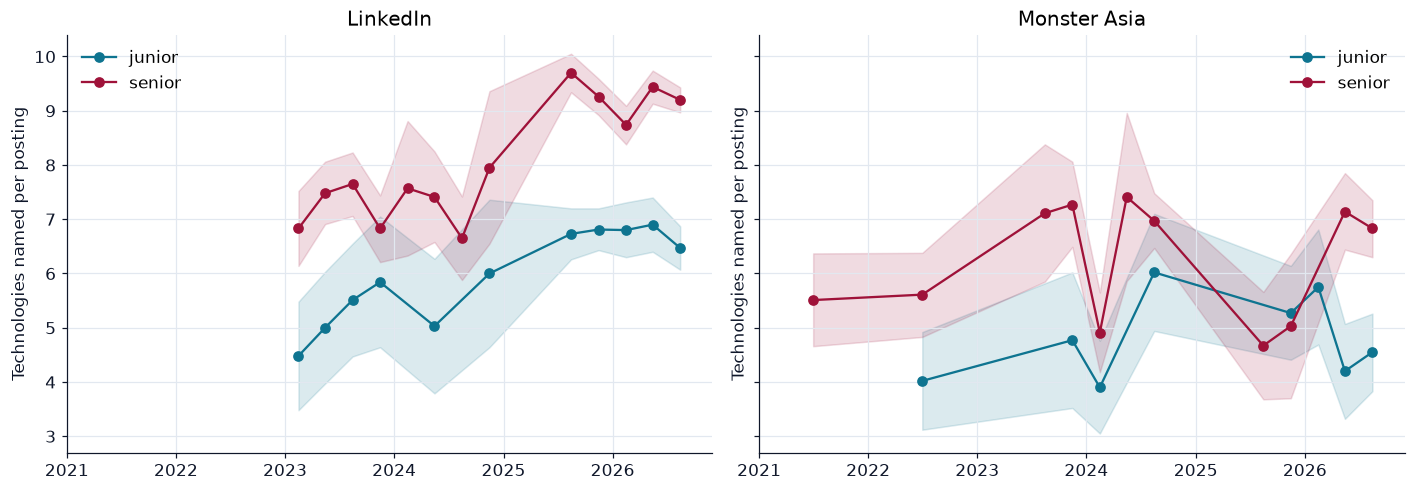

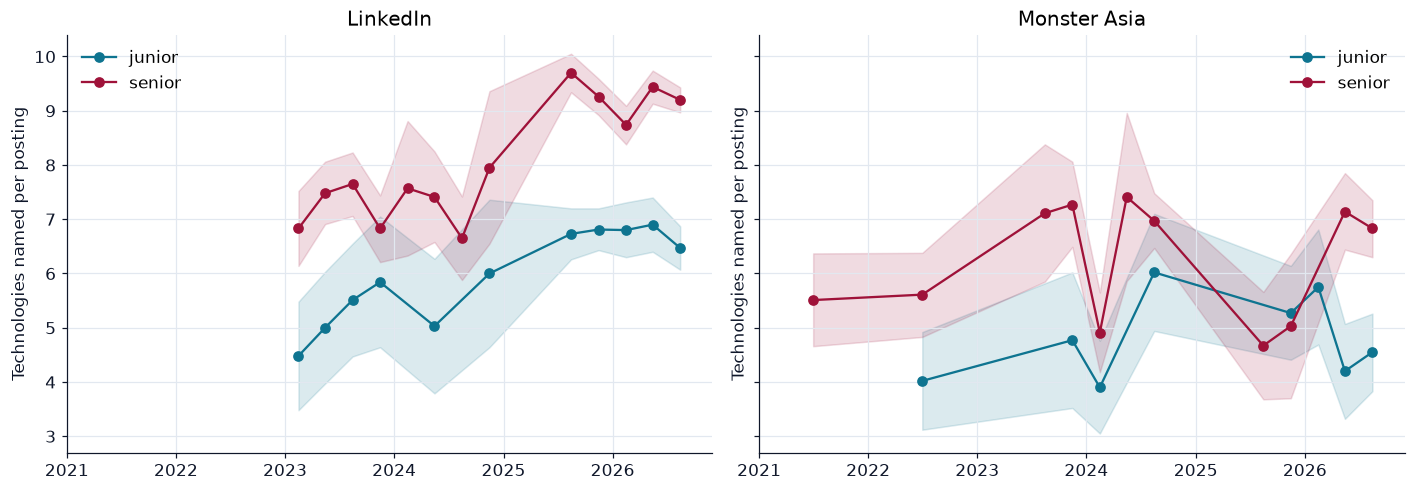

In [2]:
series = s.series_by_period(postings)
a.save_table(series.drop(columns="period_date"), "18-skill-inflation-series")
fig = s.chart_series(series)
a.save_chart(fig, "18-skill-inflation-series")
fig

## 2. Early window against late window

In [3]:
change = s.window_change(postings)
a.save_table(change, "18-skill-inflation-change")
change

,source,group,early_n,early_mean,late_n,late_mean,change,change_pct
0,LinkedIn,junior,341,5.29,2002,6.73,1.44,27.2
1,LinkedIn,senior,1175,7.26,5820,9.27,2.01,27.7
2,Monster Asia,junior,201,4.55,225,4.73,0.18,4.0
3,Monster Asia,senior,621,6.76,576,6.59,-0.17,-2.5


## 3. The junior-to-senior gap

In [4]:
gap = change.pivot(index="source", columns="group", values=["early_mean", "late_mean"])
gap["early_gap"] = (gap[("early_mean", "senior")] - gap[("early_mean", "junior")]).round(2)
gap["late_gap"] = (gap[("late_mean", "senior")] - gap[("late_mean", "junior")]).round(2)
gap = gap[["early_gap", "late_gap"]]
gap.columns = ["early_gap", "late_gap"]
gap = gap.reset_index()
a.save_table(gap, "18-skill-inflation-gap")
gap

/var/folders/gr/b7qhgnxs1tsdyx_r9qphz9740000gn/T/ipykernel_47082/563932080.py:2: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  gap["early_gap"] = (gap[("early_mean", "senior")] - gap[("early_mean", "junior")]).round(2)
/var/folders/gr/b7qhgnxs1tsdyx_r9qphz9740000gn/T/ipykernel_47082/563932080.py:3: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  gap["late_gap"] = (gap[("late_mean", "senior")] - gap[("late_mean", "junior")]).round(2)


,source,early_gap,late_gap
0,LinkedIn,1.97,2.54
1,Monster Asia,2.21,1.86


## Findings

1. **There is no skill inflation specific to juniors.** On LinkedIn, junior postings name 5.3 technologies in 2023-24 (341 postings) and 6.7 in July 2025 to September 2026 (2,002), up 27 %. Senior postings go from 7.3 (1,175) to 9.3 (5,820), up 28 %. They rise by the same proportion, so the rise is the descriptions or the mix of employers, not a shift in what juniors are asked for.
2. **Monster Asia shows no rise at all.** Junior 4.55 to 4.73 (+4 %, 201 and 225 postings), senior 6.76 to 6.59 (−2.5 %, 621 and 576). Its intervals overlap in most periods.
3. **The gap between senior and junior is stable.** About two technologies: LinkedIn 1.97 early and 2.54 late, Monster Asia 2.21 and 1.86. It widens on one source and narrows on the other, so there is no direction to report.
4. **Juniors name fewer technologies than seniors in both sources throughout**, consistent with notebook 11 (6.1 against 8.7 inside LinkedIn from 2025).
5. **Caveats.** Level is read from the title only, so this covers postings that say junior, intern or senior in the title, a minority. January to June 2025 is skipped because LinkedIn has 4 to 8 such junior postings per quarter then. A 95 % interval on a mean is an approximation for small groups.

**What this notebook cannot say:** whether junior postings ask for more than they used to in substance. A count of technologies named is not a count of skills required, and the earlier impression of a 45 % rise (2023-Q1 against 2026-Q3) came from comparing two single quarters; it does not survive pooling the windows and comparing with the senior line.